# NYC Taxi Trip Duration Prediction

**Introduction to Machine Learning — Mini Project, School of Analytics, TISS**

**Research question.** Can we predict how long an NYC taxi trip will take using only what is known when the
trip starts (pickup time, pickup zone, drop-off zone), and does knowing the taxi type (Yellow or Green)
improve the prediction?

- **Task:** regression
- **Target:** `duration_min` = drop-off time − pickup time, in minutes
- **Data:** NYC TLC Yellow and Green trip records, January–December 2025
- **Split:** chronological — Jan–Aug train, Sep–Oct validation, Nov–Dec test
- **Metrics:** MAE, RMSE, R², median absolute error

Summary: *So*

## Contents

| # | Section | What it answers |
|---|---|---|
| 1 | Setup | Libraries, paths, random seed, DuckDB connection |
| 2 | Data: first look | How many files and trips? Which columns? What is known before a trip starts? |
| 3 | Data quality and cleaning | What is missing or impossible, which rows we drop and why |
| 4 | Exploratory data analysis | How duration depends on time, place and taxi type |
| 5 | Feature engineering | Turning pickup time and zones into model inputs, without leaking the answer |
| 6 | Train / validation / test split | Chronological split and the samples we train on |
| 7 | Baseline and models | Median baseline, Linear Regression, Decision Tree, Random Forest, Gradient Boosting |
| 8 | Final evaluation on the test set | How well the chosen model does on Nov–Dec |
| 9 | Research question: does taxi type help? | Models with vs without `taxi_type`, per fleet and across fleets |
| 10 | Errors and interpretation | Where the model is wrong and which features matter |
| 11 | Limitations and responsible use | Data quality, bias, privacy, what not to conclude |
| 12 | Conclusion | Answer to the research question and future work |

## 1. Setup

In [1]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
SEED = 33
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

COLORS = {"yellow": "#D6A900", "green": "#168A62"}

In [3]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

YELLOW_FILES = str(RAW / "yellow" / "yellow_tripdata_2025-*.parquet")
GREEN_FILES = str(RAW / "green" / "green_tripdata_2025-*.parquet")
ZONES_FILE = RAW / "taxi_zone_lookup.csv"

The full year is about 49 M rows, which is too big for pandas on a laptop. We use DuckDB to query the
Parquet files directly and only bring small results (aggregates, samples) into pandas.

In [4]:
con = duckdb.connect()
con.execute("SET memory_limit = '5GB'")

def sql(query):
    return con.sql(query).df()

## 2. Data: first look

Source: [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).
One Parquet file per month per taxi type, plus a lookup table of the 265 taxi zones.
Each row is one trip.

In [5]:
files = sorted((RAW / "yellow").glob("*2025*.parquet")) + sorted((RAW / "green").glob("*2025*.parquet"))
print(len(files), "files,", round(sum(f.stat().st_size for f in files) / 1e6), "MB")

24 files, 844 MB


In [6]:
counts = sql(f'''
    SELECT 'yellow' AS taxi_type, regexp_extract(filename, '2025-([0-9][0-9])', 1)::INT AS month, count(*) AS trips
    FROM read_parquet('{YELLOW_FILES}', filename = true) GROUP BY ALL
    UNION ALL
    SELECT 'green', regexp_extract(filename, '2025-([0-9][0-9])', 1)::INT, count(*)
    FROM read_parquet('{GREEN_FILES}', filename = true) GROUP BY ALL
''')
counts = counts.pivot(index="month", columns="taxi_type", values="trips")[["yellow", "green"]]
counts.loc["total"] = counts.sum()
counts

taxi_type,yellow,green
month,,
1,3475226,48326
2,3577543,46621
3,4145257,51539
4,3970553,52132
5,4591845,55399
6,4322960,49390
7,3898963,48205
8,3574091,46306
9,4251015,48893


**Observations**
- All 12 months are there for both taxi types: 49.3 M trips in total.
- Yellow has 48.7 M trips and Green only 0.59 M, about **82 times** fewer. Any combined model will be
  dominated by Yellow, so results have to be reported per taxi type.
- Yellow volume is lowest in January (3.48 M) and highest in May (4.59 M).

In [6]:
yellow_cols = sql(f"DESCRIBE SELECT * FROM '{YELLOW_FILES}'")[["column_name", "column_type"]]
green_cols = sql(f"DESCRIBE SELECT * FROM '{GREEN_FILES}'")[["column_name", "column_type"]]

schema = yellow_cols.merge(green_cols, on="column_name", how="outer", suffixes=("_yellow", "_green"))
schema

,column_name,column_type_yellow,column_type_green
0,Airport_fee,DOUBLE,NaN
1,DOLocationID,INTEGER,INTEGER
2,PULocationID,INTEGER,INTEGER
3,RatecodeID,BIGINT,BIGINT
4,VendorID,INTEGER,INTEGER
5,cbd_congestion_fee,DOUBLE,DOUBLE
6,congestion_surcharge,DOUBLE,DOUBLE
7,ehail_fee,NaN,DOUBLE
8,extra,DOUBLE,DOUBLE
9,fare_amount,DOUBLE,DOUBLE


**Observations**
- Both files share almost the same columns. Differences: timestamp names (`tpep_` vs `lpep_`),
  `Airport_fee` (Yellow only), `ehail_fee` and `trip_type` (Green only).
- Most columns — fare, tips, tolls, surcharges, payment type, `trip_distance` — are only known **after** the
  trip. Using them would leak the answer, so they cannot be features.
- What is known at pickup: the pickup time, the pickup zone, the drop-off zone and the taxi type.

In [7]:
zones = pd.read_csv(ZONES_FILE)
print(zones.shape)
zones.Borough.value_counts()

(265, 4)


Borough
Queens           69
Manhattan        69
Brooklyn         61
Bronx            43
Staten Island    20
EWR               1
Unknown           1
Name: count, dtype: int64

263 real zones plus two placeholders (264 and 265, "Unknown"). Manhattan and Queens have 69 zones each.

## 3. Data quality and cleaning

Yellow and Green name their timestamps differently (`tpep_` vs `lpep_`). We first put both into one view
with the same column names, keeping only the columns we need. The month each row came from (its file) is
kept as `source_month`.

In [9]:
con.execute(f'''
    CREATE OR REPLACE VIEW raw AS
    SELECT 'yellow' AS taxi_type,
           regexp_extract(filename, '2025-([0-9][0-9])', 1)::INT AS source_month,
           tpep_pickup_datetime AS pickup_datetime,
           tpep_dropoff_datetime AS dropoff_datetime,
           PULocationID AS pu_zone, DOLocationID AS do_zone,
           passenger_count, trip_distance, fare_amount, payment_type
    FROM read_parquet('{YELLOW_FILES}', filename = true)
    UNION ALL
    SELECT 'green',
           regexp_extract(filename, '2025-([0-9][0-9])', 1)::INT,
           lpep_pickup_datetime, lpep_dropoff_datetime,
           PULocationID, DOLocationID,
           passenger_count, trip_distance, fare_amount, payment_type
    FROM read_parquet('{GREEN_FILES}', filename = true)
''')

sql("SELECT * FROM raw LIMIT 5")

,taxi_type,source_month,pickup_datetime,dropoff_datetime,pu_zone,do_zone,passenger_count,trip_distance,fare_amount,payment_type
0,yellow,1,2025-01-01 00:18:38,2025-01-01 00:26:59,229,237,1,1.60,10.00,1
1,yellow,1,2025-01-01 00:32:40,2025-01-01 00:35:13,236,237,1,0.50,5.10,1
2,yellow,1,2025-01-01 00:44:04,2025-01-01 00:46:01,141,141,1,0.60,5.10,1
3,yellow,1,2025-01-01 00:14:27,2025-01-01 00:20:01,244,244,3,0.52,7.20,2
4,yellow,1,2025-01-01 00:21:34,2025-01-01 00:25:06,244,116,3,0.66,5.80,2


### 3.1 Missing values

In [10]:
sql('''
    SELECT taxi_type,
           count(*) AS trips,
           round(100 * avg((pickup_datetime IS NULL)::INT), 2)  AS pickup_pct_null,
           round(100 * avg((dropoff_datetime IS NULL)::INT), 2) AS dropoff_pct_null,
           round(100 * avg((pu_zone IS NULL)::INT), 2)          AS pu_zone_pct_null,
           round(100 * avg((do_zone IS NULL)::INT), 2)          AS do_zone_pct_null,
           round(100 * avg((passenger_count IS NULL)::INT), 2)  AS passenger_pct_null,
           round(100 * avg((payment_type IS NULL)::INT), 2)     AS payment_pct_null
    FROM raw GROUP BY taxi_type
''')

,taxi_type,trips,pickup_pct_null,dropoff_pct_null,pu_zone_pct_null,do_zone_pct_null,passenger_pct_null,payment_pct_null
0,green,591375,0.00,0.00,0.00,0.00,8.43,8.43
1,yellow,48722602,0.00,0.00,0.00,0.00,23.83,0.00


**Observations**
- No missing timestamps or zones, so the target and the main features are complete.
- `passenger_count` is missing for **23.8%** of Yellow and 8.4% of Green trips. We do not use it as a feature.

### 3.2 Target: how does the raw duration look?

In [11]:
con.execute('''
    CREATE OR REPLACE VIEW raw_dur AS
    SELECT *, date_diff('second', pickup_datetime, dropoff_datetime) / 60 AS duration_min
    FROM raw
''')

sql('''
    SELECT taxi_type,
           min(duration_min) AS min,
           quantile_cont(duration_min, 0.01) AS p1,
           median(duration_min) AS median,
           quantile_cont(duration_min, 0.99) AS p99,
           quantile_cont(duration_min, 0.999) AS p99_9,
           max(duration_min) AS max
    FROM raw_dur GROUP BY taxi_type
''')

,taxi_type,min,p1,median,p99,p99_9,max
0,green,-48.83,0.05,12.50,76.70,"1,411.76","1,500.77"
1,yellow,"-51,472.32",0.00,13.48,70.85,113.85,"14,880.77"


**Observations**
- The median trip is about 13.5 min (Yellow) and 12.5 min (Green), and 99% of trips are under ~71–77 min.
- But the extremes are impossible: a Yellow trip of **−51,472 min** and one of **14,881 min** (over 10 days).
  These are recording errors, not trips, so we need cleaning rules.

### 3.3 Problem rows

In [12]:
problems = sql('''
    SELECT taxi_type,
           count(*) AS trips,
           count_if(year(pickup_datetime) <> 2025 OR month(pickup_datetime) <> source_month) AS outside_file_month,
           count_if(duration_min <= 0)   AS zero_or_negative,
           count_if(duration_min > 0 AND duration_min < 1) AS under_1_min,
           count_if(duration_min > 180)  AS over_3_hours,
           count_if(pu_zone NOT BETWEEN 1 AND 263 OR do_zone NOT BETWEEN 1 AND 263) AS unknown_zone,
           count_if(fare_amount <= 0)    AS fare_zero_or_negative
    FROM raw_dur GROUP BY taxi_type ORDER BY taxi_type DESC
''').set_index("taxi_type").astype(int)
problems

,trips,outside_file_month,zero_or_negative,under_1_min,over_3_hours,unknown_zone,fare_zero_or_negative
taxi_type,,,,,,,
yellow,48722602,214,546304,544990,18401,371657,2870234
green,591375,248,1910,19867,2707,9215,4469


In [13]:
# same table as % of each taxi type's trips
(100 * problems.div(problems.trips, axis=0)).drop(columns="trips").round(2)

,outside_file_month,zero_or_negative,under_1_min,over_3_hours,unknown_zone,fare_zero_or_negative
taxi_type,,,,,,
yellow,0.00,1.12,1.12,0.04,0.76,5.89
green,0.04,0.32,3.36,0.46,1.56,0.76


**Observations**
- Zero/negative and under-1-minute trips: 1.1% + 1.1% of Yellow, and 3.4% of Green under a minute. These
  look like cancelled trips or the meter being started and stopped.
- Over 3 hours: very rare (0.04% Yellow, 0.46% Green).
- Unknown zones (264/265): 0.8% of Yellow, 1.6% of Green.
- Wrong timestamps (pickup outside the file's month): only a few hundred rows.
- Fare ≤ 0 is the biggest group: **5.9% of Yellow**. But fare is not our target — the question is whether
  the duration of these trips is still fine.

What do the long trips and the bad-fare trips look like? If the bad-fare trips have normal durations, they
are still usable for a duration model.

In [14]:
sql('''
    SELECT 'over 3 hours' AS rows, count(*) AS trips,
           median(duration_min) AS median_duration, median(trip_distance) AS median_miles
    FROM raw_dur WHERE duration_min > 180
    UNION ALL
    SELECT 'fare <= 0', count(*), median(duration_min), median(trip_distance)
    FROM raw_dur WHERE fare_amount <= 0
    UNION ALL
    SELECT 'all trips', count(*), median(duration_min), median(trip_distance)
    FROM raw_dur
''')

,rows,trips,median_duration,median_miles
0,over 3 hours,21108,"1,392.57",2.30
1,fare <= 0,2874703,15.33,2.24
2,all trips,49313977,13.47,1.85


**Observations**
- Trips over 3 hours have a median of **1,393 minutes (23 hours) for 2.3 miles**. Nobody drives 2 miles in a
  day — the meter was left running. These have to go.
- Trips with fare ≤ 0 have a median of 15.3 min for 2.2 miles, which is a normal trip. The problem is in the
  billing, not the trip. **We keep them**, since we only predict duration.
  *(Our earlier notebook 01 dropped 2.76 M of these rows; that was only needed for a fare model.)*

In [15]:
sql('''
    SELECT taxi_type, count(*) AS trips,
           count(*) - count(DISTINCT (pickup_datetime, dropoff_datetime, pu_zone, do_zone, fare_amount, trip_distance)) AS duplicates
    FROM raw GROUP BY taxi_type
''')

,taxi_type,trips,duplicates
0,yellow,48722602,4809
1,green,591375,41


Only 4,809 Yellow and 41 Green exact duplicates — small, but we still remove them so one trip can't be counted twice.

### 3.4 Cleaning rules

Applied in this order. Each rule is checked by how many rows it removes.

1. pickup must be inside the month of its file (removes wrong timestamps, e.g. 2008 or 2026)
2. duration between 1 and 180 minutes
3. both zones between 1 and 263 (264/265 are "unknown")
4. exact duplicates removed

In [16]:
rules = {
    "raw": "TRUE",
    "pickup in file month": "year(pickup_datetime) = 2025 AND month(pickup_datetime) = source_month",
    "duration 1-180 min": "duration_min BETWEEN 1 AND 180",
    "known zones": "pu_zone BETWEEN 1 AND 263 AND do_zone BETWEEN 1 AND 263",
}

steps, where = [], []
for name, rule in rules.items():
    where.append(rule)
    n = sql(f"SELECT taxi_type, count(*) AS n FROM raw_dur WHERE {' AND '.join(where)} GROUP BY 1")
    steps.append(n.set_index("taxi_type").n.rename(name))

cleaning = pd.DataFrame(steps)[["yellow", "green"]]
cleaning

taxi_type,yellow,green
raw,48722602,591375
pickup in file month,48722388,591127
duration 1-180 min,47612696,566679
known zones,47271764,562059


In [17]:
con.execute(f'''
    COPY (
        SELECT DISTINCT taxi_type, source_month, pickup_datetime, dropoff_datetime, duration_min,
               pu_zone, do_zone, passenger_count, trip_distance, fare_amount
        FROM raw_dur
        WHERE {' AND '.join(where)}
        ORDER BY pickup_datetime
    ) TO '{PROCESSED / "trips_clean_2025.parquet"}' (FORMAT parquet)
''')

con.execute(f"CREATE OR REPLACE VIEW trips AS SELECT * FROM '{PROCESSED / 'trips_clean_2025.parquet'}'")
final = sql("SELECT taxi_type, count(*) AS n FROM trips GROUP BY 1").set_index("taxi_type").n
cleaning.loc["duplicates removed"] = final
cleaning

taxi_type,yellow,green
raw,48722602,591375
pickup in file month,48722388,591127
duration 1-180 min,47612696,566679
known zones,47271764,562059
duplicates removed,47269050,562029


In [18]:
removed = cleaning.diff().iloc[1:].abs().astype(int)
removed.loc["total removed"] = removed.sum()
kept_pct = (100 * cleaning.iloc[-1] / cleaning.loc["raw"]).round(2)

display(removed)
print("kept (%):", kept_pct.to_dict())

taxi_type,yellow,green
pickup in file month,214,248
duration 1-180 min,1109692,24448
known zones,340932,4620
duplicates removed,2714,30
total removed,1453552,29346


kept (%): {'yellow': 97.02, 'green': 95.04}


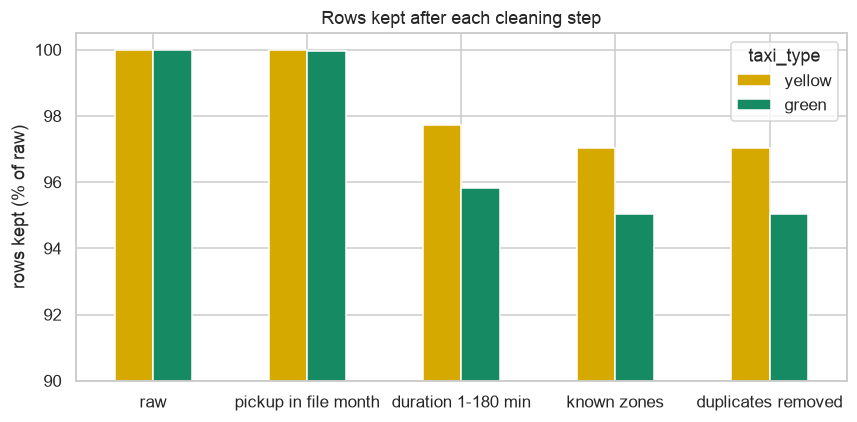

In [19]:
pct = 100 * cleaning / cleaning.loc["raw"]

ax = pct.plot(kind="bar", color=[COLORS["yellow"], COLORS["green"]], figsize=(8, 4), rot=0)
ax.set_ylim(90, 100.5)
ax.set_ylabel("rows kept (% of raw)")
ax.set_title("Rows kept after each cleaning step")
plt.tight_layout()
plt.savefig(FIGURES / "cleaning_steps.png")
plt.show()

**Observations**
- We keep **97.0% of Yellow** (47.27 M) and **95.0% of Green** (0.56 M) trips: **47.83 M trips** in total.
- The duration rule removes the most rows (1.1 M Yellow). Green loses relatively more, mostly
  under-1-minute trips.
- The clean table is saved to `data/processed/trips_clean_2025.parquet`; everything after this reads from it.

**What we are giving up:** very short trips and meters left running are excluded, so the model is only
meant for ordinary trips of 1 minute to 3 hours.

## 4. Exploratory data analysis

Goal: understand what makes a trip long or short, using only things we know at pickup.
All queries run on the clean table (`trips` view) in DuckDB.

### 4.1 Distribution of the target

Is duration skewed? If yes, MAE and median error are more honest than the mean, and a log target is worth
trying.

In [20]:
# TODO: summary stats of duration_min per taxi_type (p10, p25, median, p75, p90, p99, mean, std)

In [21]:
# TODO: take a ~300k random sample (USING SAMPLE ... (reservoir, SEED)) and plot two histograms side by side:
#   - duration in minutes (0-120)
#   - log(1 + duration)
# Plot each taxi type as % of its own trips (Yellow has 80x more trips, raw counts would hide Green).
# Save to FIGURES / "duration_distribution.png"

**Observations**
- *(fill in after running the cell above)*

### 4.2 Time of day and day of week

Does the hour or the weekday change how long trips take?

In [22]:
# TODO: median duration and number of trips by pickup hour, per taxi_type -> line plot (two panels: trips, median duration)

**Observations**
- *(fill in after running the cell above)*

In [23]:
# TODO: heatmap of median duration, rows = day of week (Mon-Sun), columns = pickup hour

**Observations**
- *(fill in after running the cell above)*

### 4.3 Trend over the year

Our split is chronological, so if trips get slower over the year the test months (Nov–Dec) will be harder
than the training months.

In [24]:
# TODO: median duration and trips per month, per taxi_type -> line plot

**Observations**
- *(fill in after running the cell above)*

### 4.4 Geography: zones and boroughs

Where trips start and end should matter most: a trip inside Manhattan is not a trip to JFK.

In [25]:
# TODO: join the zone lookup (pu_zone -> Borough, Zone) and show the top 10 pickup zones per taxi_type with % of trips

**Observations**
- *(fill in after running the cell above)*

In [26]:
# TODO: pickup borough x drop-off borough: number of trips and median duration -> heatmap of median duration

**Observations**
- *(fill in after running the cell above)*

### 4.5 Yellow vs Green

The two fleets serve different parts of the city. How different are they?

In [27]:
# TODO: one comparison table per taxi_type: trips, % Manhattan pickups, % airport trips, % cross-borough,
# median duration, p90 duration

**Observations**
- *(fill in after running the cell above)*

### 4.6 What the EDA means for modelling

*(fill in: 4-6 bullets, e.g. which features to build, which metric to lead with, what to watch out for)*

## 5. Feature engineering

Rule: a feature may only use information available **when the trip starts** — pickup time, pickup zone,
drop-off zone and taxi type. Anything measured during or after the trip (`trip_distance`, fare, drop-off
time) is not allowed.

### 5.1 Zone centroids and distance

We don't know the route, but we can estimate the distance between the centres of the two zones from the
TLC zone shapefile (`data/raw/taxi_zones.zip`).

In [28]:
# TODO: read the shapefile with geopandas (it is in feet, EPSG:2263), take each zone's centroid,
# convert to km -> table: zone_id, x_km, y_km. Zones 264/265 have no shape.

In [29]:
# TODO: register the centroid table in DuckDB (con.register) and check: distance JFK (132) -> Times Sq (230) ~ 20 km?

**Observations**
- *(fill in after running the cell above)*

### 5.2 Time features

Hour, weekday, weekend, rush hour and public holidays. Hour is also encoded as sin/cos so that 23:00 and
00:00 are close together. We do **not** use `month`: the test months (Nov–Dec) never appear in training.

In [30]:
# TODO: list of 2025 US / NY holidays (holidays library) -> DuckDB table

### 5.3 Route history from earlier months

The strongest signal is how long the same route (pickup zone -> drop-off zone) took **before**. To avoid
leakage, a trip in month *m* only uses trips from months 1 … *m*−1. History is pooled across both taxi types,
so the "without taxi type" model cannot learn the fleet through this feature.

In [31]:
# TODO: route x month table: trips and sum of duration per (pu_zone, do_zone, month)
# then a window: SUM(...) OVER (PARTITION BY pu_zone, do_zone ORDER BY month
#                                 ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
# -> route_prior_mean, route_prior_trips
# Same idea per pickup zone (fallback for routes never seen before).

In [32]:
# TODO: leakage check: rebuild the history using only months 1-3 and check month 3 is identical to the full build

**Observations**
- *(fill in after running the cell above)*

### 5.4 Final feature table

In [33]:
# TODO: one query joining trips + time features + borough/airport flags + centroid distance + route history
# -> COPY to data/processed/features_2025.parquet

In [34]:
# TODO: print the feature list: allowed features vs. columns we keep only for analysis

| Feature | Used | Why |
|---|---|---|
| pickup hour, weekday, weekend, rush hour, holiday, hour sin/cos | yes | known at pickup |
| pickup / drop-off zone, borough, airport flags | yes | known at pickup |
| centroid distance | yes | estimated from the zones, not the meter |
| route history (earlier months only) | yes | built only from the past |
| taxi type | yes / no | this is what the research question tests |
| month | no | test months not in training |
| passenger_count | no | ~24% missing in Yellow |
| trip_distance, fare, tips, tolls, drop-off time | no | only known after the trip |

## 6. Train / validation / test split

| Set | Months | Used for |
|---|---|---|
| Train | Jan–Aug | fitting the models |
| Validation | Sep–Oct | choosing models and settings |
| Test | Nov–Dec | final score, used **once** |

A random split would let the model see the future; a chronological split copies how the model would
really be used.

In [35]:
# TODO: count trips per split and taxi type

### 6.1 Sampling

47 M rows do not fit in memory for scikit-learn. We train on a fixed-seed random sample and keep all
Green trips, so Green is not lost. Validation and test samples are drawn the same way.

In [36]:
# TODO: sample train / validation / test into pandas (fixed SEED), print sizes per taxi type
# TODO: define FEATURES list, X_train, y_train, X_val, y_val, X_test, y_test

## 7. Baseline and models

Every model has to beat a simple baseline, otherwise it is not learning anything useful.

In [37]:
# TODO: helper function evaluate(y_true, y_pred) -> MAE, RMSE, R2, median AE

### 7.1 Baselines

In [38]:
# TODO: baseline 1 = median duration of the training set for every trip
# TODO: baseline 2 = median duration of the same route in training (fallback: overall median)

**Observations**
- *(fill in after running the cell above)*

### 7.2 Linear Regression

In [39]:
# TODO: Pipeline(ColumnTransformer(one-hot boroughs, scale numbers), LinearRegression()) -> evaluate on validation

### 7.3 Decision Tree

In [40]:
# TODO: try a few max_depth values, pick the best on validation

### 7.4 Random Forest

In [41]:
# TODO: smaller sample (e.g. 300k rows), n_estimators ~100, n_jobs=-1 -> evaluate on validation

### 7.5 Histogram Gradient Boosting

In [42]:
# TODO: try a few learning_rate / max_leaf_nodes values -> evaluate on validation

### 7.6 Comparison on validation

In [43]:
# TODO: one table with all models (rows) x metrics (columns), sorted by MAE + bar chart of MAE

**Observations**
- *(fill in after running the cell above)*

## 8. Final evaluation on the test set

Retrain the chosen model on train + validation (Jan–Oct) and score it once on Nov–Dec.

In [44]:
# TODO: refit best model on Jan-Oct, predict Nov-Dec, evaluate overall and per taxi type, compare with baseline

**Observations**
- *(fill in after running the cell above)*

## 9. Research question: does knowing the taxi type help?

| Experiment | Train | Test | Question |
|---|---|---|---|
| C1 | Yellow + Green, **with** `taxi_type` | Yellow + Green | |
| C2 | Yellow + Green, **without** `taxi_type` | Yellow + Green | C1 vs C2: does taxi type add information? |
| A / B | Yellow only / Green only | same fleet | does a fleet-specific model do better? |
| D / E | Yellow / Green | the other fleet | does one fleet's model work on the other? |

Same model, same rows, same test set — only the training data or the `taxi_type` column changes.

In [45]:
# TODO: train C1 and C2 with the best model, evaluate each per taxi type -> table

In [46]:
# TODO: train A (Yellow only) and B (Green only), test D (Yellow model on Green) and E (Green model on Yellow)

In [47]:
# TODO: one results table with all experiments + bar chart of MAE per experiment and fleet

**Observations**
- *(fill in after running the cell above)*

**Answer to the research question:** *(fill in)*

## 10. Errors and interpretation

In [48]:
# TODO: predicted vs actual (hexbin) and residual histogram on the test set

**Observations**
- *(fill in after running the cell above)*

In [49]:
# TODO: MAE by pickup borough, by hour and by trip length bucket -> where is the model worse?

**Observations**
- *(fill in after running the cell above)*

In [50]:
# TODO: permutation importance on a test sample -> bar chart of the top features

**Observations**
- *(fill in after running the cell above)*

## 11. Limitations and responsible use

- **Data privacy:** *(public, de-identified TLC data; locations only at zone level)*
- **Bias and fairness:** *(do errors differ by borough or taxi type? Green has far less data)*
- **Interpretability:** *(which features matter; importance ≠ cause)*
- **Overclaiming:** *(we predict duration, we do not explain why trips are slow)*
- **Practical use:** *(an estimate, not a navigation ETA; no live traffic, weather or route)*
- **Data limits:** *(cleaning removed very short/long trips; one year only; test months are slower)*

## 12. Conclusion

- *(answer to the research question in 2-3 sentences)*
- *(best model and its test MAE vs the baseline, in plain words)*
- *(what we would do next: live traffic, weather, fare estimate in the Streamlit app)*

**References**
- NYC Taxi & Limousine Commission, TLC Trip Record Data, 2025. https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
- Pedregosa et al. (2011), Scikit-learn: Machine Learning in Python, JMLR 12.